10 total cells and 28 total surfaces.

(Could not find where cell 9 is, or surface 25).

In [1]:
import openmc

# Surface definitions
s1 = openmc.model.RightCircularCylinder((0,-10,5),2,0.5,'y')
s2 = openmc.model.RightCircularCylinder((0,-8,5),3,1,'y')
s3 = openmc.YPlane(y0=-5)
s4 = openmc.YPlane(y0=-3.5)
s5 = openmc.YPlane(y0=-2)
s6 = openmc.YPlane(y0=0)
s7 = openmc.YPlane(y0=2)
s8 = openmc.YPlane(y0=5)
s9 = openmc.YPlane(y0=9)

s26 = openmc.model.RightCircularCylinder((0,5,7),3, 1.5,'y')

s10 = openmc.YPlane(y0=15)
s11 = openmc.ZPlane(z0=9)
s12 = openmc.ZPlane(z0=0)
s13 = openmc.ZPlane(z0=10)
s14 = openmc.ZPlane(z0=-8)
s15 = openmc.XPlane(x0=3)
s16 = openmc.XPlane(x0=-3)
s17 = openmc.XPlane(x0=4)
s18 = openmc.XPlane(x0=-4)
s19 = openmc.XPlane(x0=5)
s20=openmc.XPlane(x0=-5)

s21 = openmc.XPlane(x0=6)
s22 = openmc.XPlane(x0=-6)

s27 = openmc.Plane(0,1/3, 1, -2)
s28 = openmc.Sphere(r=25)

In [2]:
# Cell definitions
c1 = openmc.Cell(fill=None,region=-s1)
c2 = openmc.Cell(fill=None,region=-s2)
c3 = openmc.Cell(fill=None,region=+s3 & +s12 & -s11 & -s5 & -s15 & +s16)
c4 = openmc.Cell(fill=None,region=+s5 & -s6 & +s12 & -s11 & -s17 & +s18)
c5= openmc.Cell(fill=None,region=+s6 & -s8 & -s13 & + s12 & -s19 & +s20)
c6 = openmc.Cell(fill=None,region=-s26)
c7 = openmc.Cell( fill=None,region=+s27 & -s7 & -s12 & +s4 & +s16 & -s17)
c8 = openmc.Cell(fill=None,region=+s7 & +s14 & -s12 & -s10 & +s22 & -  s21)

c10 = openmc.Cell(fill=None,region=-s28 & ~(c1.region | c2.region | c3.region | c4.region | c5.region | c6.region | c7.region | c8.region))
geometry=openmc.Geometry([c1, c2,c3,c4, c5,c6,c7, c8,c10 ])

# use to get rid of duplicate surfaces from using macrobodies from openmc.model

#print(geometry.get_all_surfaces())
geometry.export_to_xml()

In [3]:
material=openmc.Materials()
material.export_to_xml()

setting = openmc.Settings()
setting.export_to_xml()

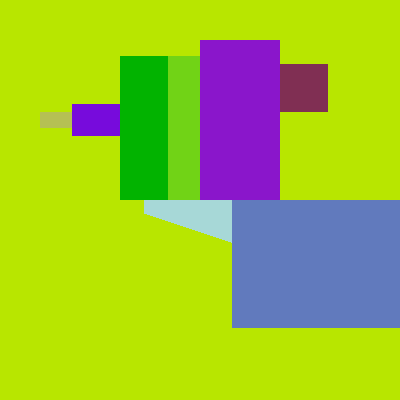

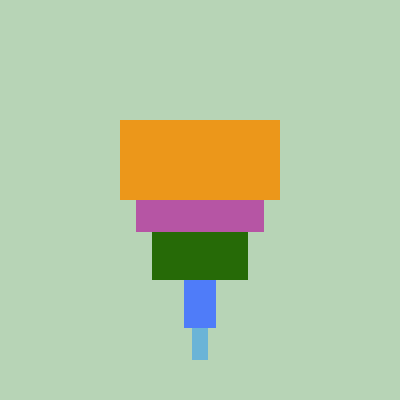

In [4]:
w = 25
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'

plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 5.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'

plots.append(plot)
openmc.plot_inline(plots)
